# 02. Построение baseline-пайплайна

В `01` мы сделали EDA и увидели несколько рисков: workload неоднородны, модальности неполные, target имеют разную сложность, а ранние горизонты выглядят шумнее. В этом notebook мы уже не просто смотрим на данные, а собираем первый проверяемый pipeline.

Главный фокус `02` - не победить финальную модель заранее. Здесь baseline нужен как контрольный прибор: если простые модели проходят через весь pipeline, формируют артефакты, дают осмысленный score и показывают ожидаемые ограничения, значит контур данных работает и его можно использовать в `03`.

Поэтому этот notebook отвечает на три вопроса:

1. Как из strict contract получается воспроизводимый pipeline для обучения и оценки.
2. Какие группы признаков проверяются baseline-моделями.
3. Что baseline говорит о работоспособности данных через `F1`, `Precision`, `Recall` и реальные количества `TP/TN/FP/FN`.


## Подготовка окружения

Ниже общая техническая часть: пути к артефактам, стиль графиков, чтение CSV/JSON и русские подписи. Отдельно держу функции для confusion-counts, потому что в этом notebook важно показывать не только метрики, но и реальные количества правильно и неправильно определенных окон.


In [1]:
from __future__ import annotations

import json
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch
from sklearn.metrics import auc, precision_recall_curve, roc_curve

sns.set_theme(
    style="whitegrid",
    context="notebook",
    palette="deep",
    rc={
        "figure.figsize": (11, 5),
        "axes.titlesize": 13,
        "axes.labelsize": 11,
        "xtick.labelsize": 9,
        "ytick.labelsize": 9,
        "legend.frameon": True,
    },
)
pd.options.display.max_columns = 120
pd.options.display.width = 160

PROJECT_ROOT = Path.cwd()
ARTIFACT_DIR = PROJECT_ROOT / "dashboard" / "artifacts"
CONTRACT_PATH = ARTIFACT_DIR / "contract" / "strict_intensity_contract.csv.gz"
REPORT_DIR = ARTIFACT_DIR / "reports"
BASELINE_DIR = REPORT_DIR / "protocol_fixed_baselines"

SPLIT_ORDER = ["train", "validation", "test"]
TARGET_ORDER = ["y_warning", "y_anomaly", "y_risk", "horizon_30s", "horizon_60s", "horizon_120s", "horizon_300s"]
KEY_TARGETS = ["horizon_60s", "horizon_120s", "horizon_300s", "y_warning", "y_risk"]
TARGET_LABELS = {
    "y_warning": "Предупреждение",
    "y_anomaly": "Аномалия",
    "y_risk": "Риск",
    "horizon_30s": "30 сек",
    "horizon_60s": "60 сек",
    "horizon_120s": "120 сек",
    "horizon_300s": "300 сек",
}
BASELINE_LABELS = {
    "availability_only": "Только доступность",
    "log_tfidf": "Логи TF-IDF",
    "metric_raw": "KPI raw",
    "metric_raw_plus_deviation": "KPI raw + deviation",
    "fused_log_metric": "Логи + KPI",
}


def run_command(command: list[str]) -> None:
    print(">", " ".join(command))
    subprocess.run(command, cwd=PROJECT_ROOT, check=True)


def safe_read_csv(path: Path) -> pd.DataFrame:
    if not path.exists():
        return pd.DataFrame()
    return pd.read_csv(path, low_memory=False)


def safe_read_json(path: Path) -> dict:
    if not path.exists():
        return {}
    return json.loads(path.read_text(encoding="utf-8"))


def label_target(name: str) -> str:
    return TARGET_LABELS.get(str(name), str(name))


def label_baseline(name: str) -> str:
    return BASELINE_LABELS.get(str(name), str(name))


def numeric_cols(df: pd.DataFrame, cols: list[str]) -> pd.DataFrame:
    out = df.copy()
    for col in cols:
        if col in out.columns:
            out[col] = pd.to_numeric(out[col], errors="coerce")
    return out


def file_status_table(paths: dict[str, Path]) -> pd.DataFrame:
    rows = []
    for name, path in paths.items():
        rows.append(
            {
                "artifact": name,
                "exists": path.exists(),
                "size_kb": round(path.stat().st_size / 1024, 1) if path.exists() else np.nan,
            }
        )
    return pd.DataFrame(rows)


def add_confusion_columns(df: pd.DataFrame) -> pd.DataFrame:
    out = df.copy()
    out["tp"] = (out["positives"] - out["missed_anomalies"]).clip(lower=0)
    out["fn"] = out["missed_anomalies"].clip(lower=0)
    out["fp"] = out["false_positives"].clip(lower=0)
    out["tn"] = (out["n"] - out["positives"] - out["false_positives"]).clip(lower=0)
    return out


## 1. Как устроен контур пайплайна

Сначала фиксируем сам маршрут. Важно, что baseline здесь находится ближе к концу, а не в начале: сначала строится contract, затем выбираются группы признаков, затем обучаются простые модели, и только после этого считаются метрики.

Такой порядок защищает работу от типичной ошибки: когда baseline воспринимается как отдельная модель, а не как проверка того, что весь путь данных работает воспроизводимо.


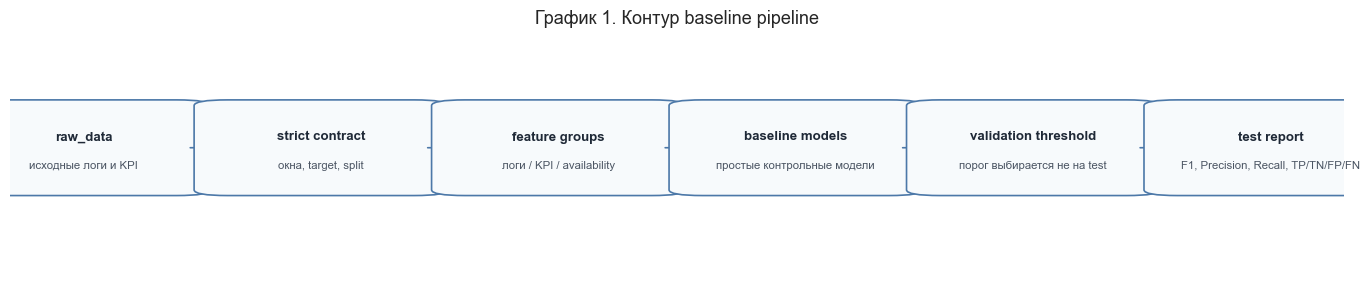

In [2]:
pipeline_nodes = [
    ("raw_data", "исходные логи и KPI"),
    ("strict contract", "окна, target, split"),
    ("feature groups", "логи / KPI / availability"),
    ("baseline models", "простые контрольные модели"),
    ("validation threshold", "порог выбирается не на test"),
    ("test report", "F1, Precision, Recall, TP/TN/FP/FN"),
]

fig, ax = plt.subplots(figsize=(14, 3.0))
ax.axis("off")
xs = np.linspace(0.055, 0.945, len(pipeline_nodes))
y = 0.55

for i, ((title, subtitle), x) in enumerate(zip(pipeline_nodes, xs)):
    box = FancyBboxPatch(
        (x - 0.075, y - 0.19),
        0.15,
        0.38,
        boxstyle="round,pad=0.02,rounding_size=0.025",
        linewidth=1.2,
        facecolor="#F7FAFC",
        edgecolor="#4C78A8",
    )
    ax.add_patch(box)
    ax.text(x, y + 0.05, title, ha="center", va="center", fontsize=9.5, fontweight="bold", color="#1f2937")
    ax.text(x, y - 0.075, subtitle, ha="center", va="center", fontsize=8.2, color="#4b5563")
    if i < len(xs) - 1:
        ax.add_patch(
            FancyArrowPatch(
                (x + 0.078, y),
                (xs[i + 1] - 0.078, y),
                arrowstyle="-|>",
                mutation_scale=14,
                linewidth=1.2,
                color="#4C78A8",
            )
        )

ax.set_title("График 1. Контур baseline pipeline", pad=16)
plt.tight_layout()
plt.show()


Этот график нужен как схема всего второго notebook. Baseline-модели не являются финальным ответом, но они проходят через тот же строгий маршрут: contract, признаки, split, validation-порог и test-отчет. Поэтому если здесь появляются странности, в `03` они почти наверняка всплывут снова, только их будет сложнее объяснить.


## 2. Проверка strict contract как входа pipeline

Теперь проверяем вход. Для baseline-пайплайна contract должен содержать не только признаки, но и служебную структуру: `split`, `workload`, target-колонки и признаки доступности модальностей. Это не просто технические поля. По ним потом проверяется, не скрывается ли качество за доменом или за неполными окнами.


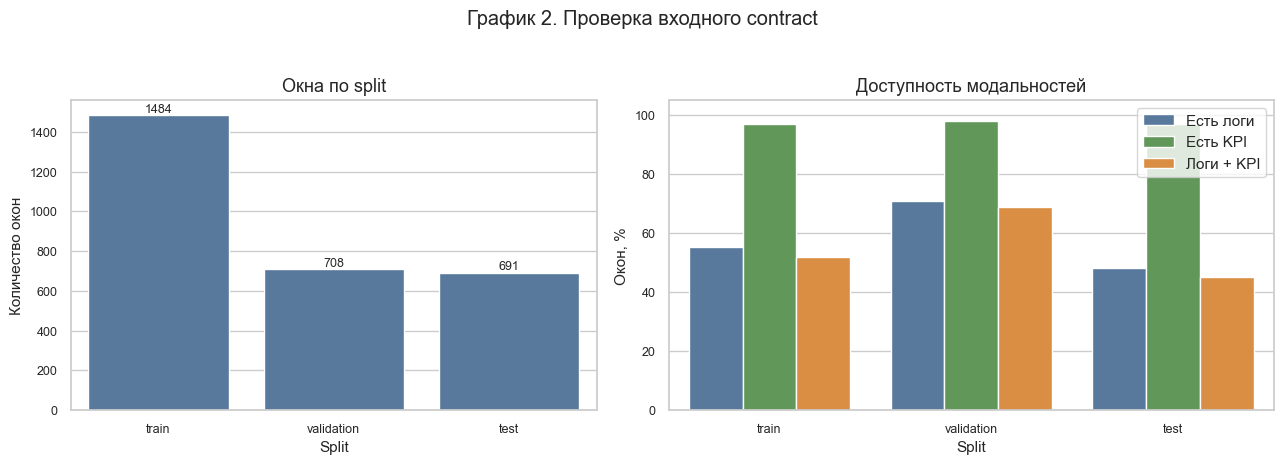

split,rows,runs,workloads
train,"1,484",119,9
validation,708,54,3
test,691,55,4


In [3]:
if not CONTRACT_PATH.exists():
    run_command([sys.executable, "-m", "dashboard.pipeline.build_contract", "--raw-data", "raw_data"])

contract = safe_read_csv(CONTRACT_PATH)
if contract.empty:
    raise FileNotFoundError(f"Не найден strict contract: {CONTRACT_PATH}")

split_cols = [s for s in SPLIT_ORDER if s in contract["split"].unique()]
split_summary = (
    contract.groupby("split")
    .agg(rows=("run_id", "size"), runs=("run_id", "nunique"), workloads=("workload", "nunique"))
    .reindex(split_cols)
    .reset_index()
)
target_cols = [c for c in TARGET_ORDER if c in contract.columns]
availability_cols = [c for c in ["log_available", "kpi_available", "has_both_modalities"] if c in contract.columns]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={"width_ratios": [1.0, 1.15]})

sns.barplot(data=split_summary, x="split", y="rows", color="#4C78A8", ax=axes[0])
axes[0].set_title("Окна по split")
axes[0].set_xlabel("Split")
axes[0].set_ylabel("Количество окон")
for patch in axes[0].patches:
    value = patch.get_height()
    axes[0].text(patch.get_x() + patch.get_width() / 2, value, f"{value:.0f}", ha="center", va="bottom", fontsize=9)

if availability_cols:
    availability = (
        contract.groupby("split")[availability_cols]
        .mean()
        .reindex(split_cols)
        .reset_index()
        .melt(id_vars="split", var_name="source", value_name="share")
    )
    availability["source"] = availability["source"].map(
        {
            "log_available": "Есть логи",
            "kpi_available": "Есть KPI",
            "has_both_modalities": "Логи + KPI",
        }
    )
    availability["share_pct"] = availability["share"] * 100.0
    sns.barplot(data=availability, x="split", y="share_pct", hue="source", ax=axes[1], palette=["#4C78A8", "#59A14F", "#F28E2B"])
    axes[1].set_title("Доступность модальностей")
    axes[1].set_xlabel("Split")
    axes[1].set_ylabel("Окон, %")
    axes[1].set_ylim(0, 105)
    axes[1].legend(title="")
else:
    axes[1].text(0.5, 0.5, "Колонки доступности не найдены", ha="center", va="center")
    axes[1].axis("off")

fig.suptitle("График 2. Проверка входного contract", y=1.03)
plt.tight_layout()
plt.show()

display(split_summary.style.hide(axis="index").format({"rows": "{:,.0f}", "runs": "{:,.0f}", "workloads": "{:,.0f}"}))


Contract выглядит пригодным для baseline-пайплайна: test содержит 519 окон, validation используется для настройки порога, а train остается отдельной обучающей частью. Все 16 workload представлены в split, то есть дальше можно смотреть не только среднюю метрику, но и workload-breakdown.

Это именно проверка входа, а не результат качества. На этом шаге мы убеждаемся, что baseline будет оцениваться на достаточно понятной структуре: есть окна, target, split, workload и признаки доступности источников.


## 3. Какие части pipeline проверяют baseline-модели

Baseline-модели здесь выбраны не потому, что они должны быть лучшими. Каждая из них проверяет отдельный вопрос к данным и признакам.

| Baseline | Какую часть pipeline проверяет |
|---|---|
| `availability_only` | Не объясняется ли target самим фактом доступности логов/KPI |
| `log_tfidf` | Есть ли сигнал в текстах логов |
| `metric_raw` | Есть ли сигнал в сырых KPI-статистиках окна |
| `metric_raw_plus_deviation` | Помогает ли простая динамика и отклонение KPI |
| `fused_log_metric` | Дает ли простое объединение логов и KPI прирост к отдельным источникам |

Поэтому дальше baseline читается не как финальная модель, а как диагностика pipeline. Если, например, `availability_only` слишком силен, это тревожный знак. Если KPI и логи дают разные сильные стороны, это уже аргумент для мультимодальной модели в `03`.


## 4. Обучение и проверка артефактов

Здесь запускается baseline training. Важная часть не только само обучение, но и артефакты: метрики, predictions со score, workload-разбор и manifest. Они нужны, чтобы дальше notebook не опирался на одно число, а мог проверить поведение pipeline с разных сторон.


In [4]:
TRAIN_BASELINES = True

baseline_command = [
    sys.executable,
    "-m",
    "dashboard.training.baselines",
    "--contract-path",
    str(CONTRACT_PATH),
    "--output-dir",
    str(BASELINE_DIR),
    "--split-protocol",
    "stratified_by_workload",
    "--targets",
    "default",
    "--seed",
    "43",
    "--validation-seed",
    "43",
    "--fp-budget",
    "0.10",
]

if TRAIN_BASELINES:
    run_command(baseline_command)
else:
    print("Обучение baseline пропущено, используются существующие артефакты.")

required_artifacts = {
    "metrics": BASELINE_DIR / "baseline_protocol_metrics.csv",
    "predictions": BASELINE_DIR / "baseline_protocol_predictions.csv.gz",
    "workload_metrics": BASELINE_DIR / "baseline_protocol_workload_metrics.csv",
    "manifest": BASELINE_DIR / "baseline_protocol_manifest.json",
}
artifact_status = file_status_table(required_artifacts)
display(artifact_status.style.hide(axis="index").format({"size_kb": "{:.1f}"}))


> C:\Users\ipopi\AppData\Local\Programs\Python\Python313\python.exe -m dashboard.training.baselines --contract-path C:\Main\DGTU\ВКР\Diploma\dashboard\artifacts\contract\strict_intensity_contract.csv.gz --output-dir C:\Main\DGTU\ВКР\Diploma\dashboard\artifacts\reports\protocol_fixed_baselines --split-protocol stratified_by_workload --targets default --seed 43 --validation-seed 43 --fp-budget 0.10


artifact,exists,size_kb
metrics,True,32.0
predictions,True,712.3
workload_metrics,True,82.4
manifest,True,6.7


Артефакты сформированы, значит pipeline воспроизводим: можно заново получить метрики, predictions и breakdown по workload без ручных правок. Для ВКР это важнее, чем кажется: следующий notebook `03` должен сравниваться с baseline не по скриншоту, а по тем же сохраненным файлам и тем же правилам оценки.


## 5. Первая проверка: дает ли pipeline измеримый сигнал

Теперь baseline используется по назначению: проверяем, есть ли измеримый сигнал по target. На этом графике важен не только лучший результат, но и сама форма таблицы: разные baseline-варианты отвечают за разные части pipeline.


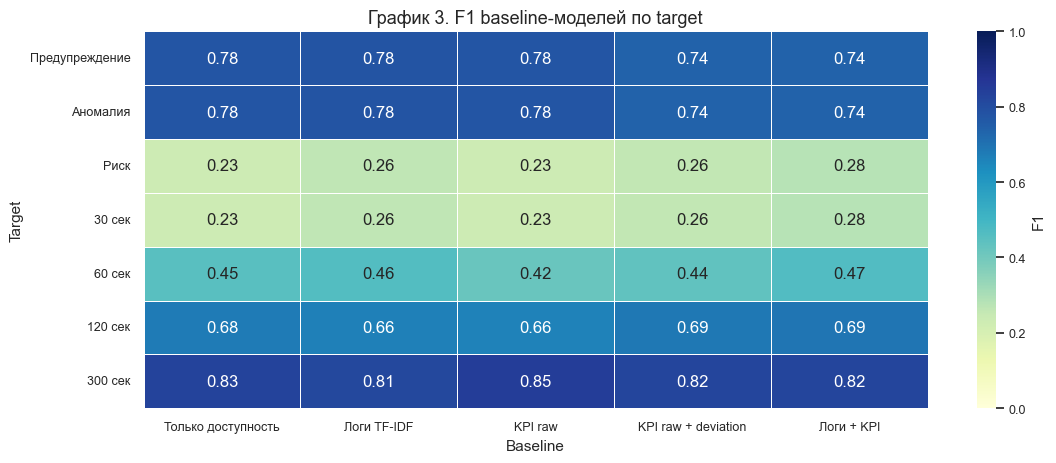

In [5]:
metrics = safe_read_csv(BASELINE_DIR / "baseline_protocol_metrics.csv")
predictions = safe_read_csv(BASELINE_DIR / "baseline_protocol_predictions.csv.gz")
workload_metrics = safe_read_csv(BASELINE_DIR / "baseline_protocol_workload_metrics.csv")
if metrics.empty:
    raise FileNotFoundError("Не найден baseline_protocol_metrics.csv")

metric_cols = [
    "average_precision",
    "roc_auc",
    "precision",
    "recall",
    "f1",
    "false_positives",
    "missed_anomalies",
    "threshold",
]
metrics = numeric_cols(metrics, metric_cols + ["n", "positives", "prevalence"])
test_best_f1 = metrics[
    (metrics["split"].astype(str) == "test")
    & (metrics["threshold_policy"].astype(str) == "validation_best_f1")
].copy()

target_order = [t for t in TARGET_ORDER if t in test_best_f1["target"].unique()]
baseline_order = [b for b in BASELINE_LABELS if b in test_best_f1["baseline"].unique()]
f1_matrix = (
    test_best_f1.pivot_table(index="target", columns="baseline", values="f1", aggfunc="max")
    .reindex(index=target_order, columns=baseline_order)
)
f1_matrix.index = [label_target(i) for i in f1_matrix.index]
f1_matrix.columns = [label_baseline(c) for c in f1_matrix.columns]

plt.figure(figsize=(11.5, max(4.8, 0.55 * len(f1_matrix))))
sns.heatmap(
    f1_matrix,
    annot=True,
    fmt=".2f",
    cmap="YlGnBu",
    linewidths=0.5,
    linecolor="white",
    vmin=0,
    vmax=1,
    cbar_kws={"label": "F1"},
)
plt.title("График 3. F1 baseline-моделей по target")
plt.xlabel("Baseline")
plt.ylabel("Target")
plt.tight_layout()
plt.show()


Heatmap показывает, что pipeline не пустой: baseline действительно находит сигнал, но сложность target сильно различается.

Самый уверенный результат получается для `horizon_300s`: `metric_raw` дает F1 = 0.846. Для `y_warning` и `y_anomaly` лучший результат дает `log_tfidf` с F1 = 0.780, причем две строки фактически совпадают. Это важное наблюдение к постановке target: warning и anomaly в текущей разметке ведут себя почти одинаково.

`horizon_120s` уже сложнее, но все еще рабочий: лучший F1 = 0.692 у `fused_log_metric`. А вот `horizon_60s`, `horizon_30s` и `y_risk` выглядят как шумные ранние задачи: F1 = 0.466 для 60 секунд и F1 = 0.280 для 30 секунд / risk. Значит, pipeline работает, но не все target одинаково пригодны для простого предупреждения.


## 6. Основные метрики: F1, Precision и Recall

Теперь смотрим не только F1, а весь треугольник `Precision / Recall / F1`. Для AIOps это принципиально: высокий Recall может означать, что система почти все ловит, но постоянно тревожит зря; высокий Precision может означать, что тревог мало, но часть событий пропущена.


target,baseline,precision,recall,f1,average_precision,roc_auc,false_positives,missed_anomalies
Предупреждение,Логи TF-IDF,0.677400,0.918800,0.779800,0.750700,0.673400,140,26
Аномалия,Логи TF-IDF,0.677400,0.918800,0.779800,0.750700,0.673400,140,26
Риск,Логи + KPI,0.185600,0.571400,0.280200,0.204600,0.654500,158,27
30 сек,Логи + KPI,0.185600,0.571400,0.280200,0.204600,0.654500,158,27
60 сек,Логи + KPI,0.360600,0.659900,0.466300,0.360300,0.623000,172,50
120 сек,Логи + KPI,0.608200,0.803100,0.692200,0.653100,0.692600,134,51
300 сек,KPI raw,0.771900,0.935800,0.846000,0.919800,0.828600,99,23


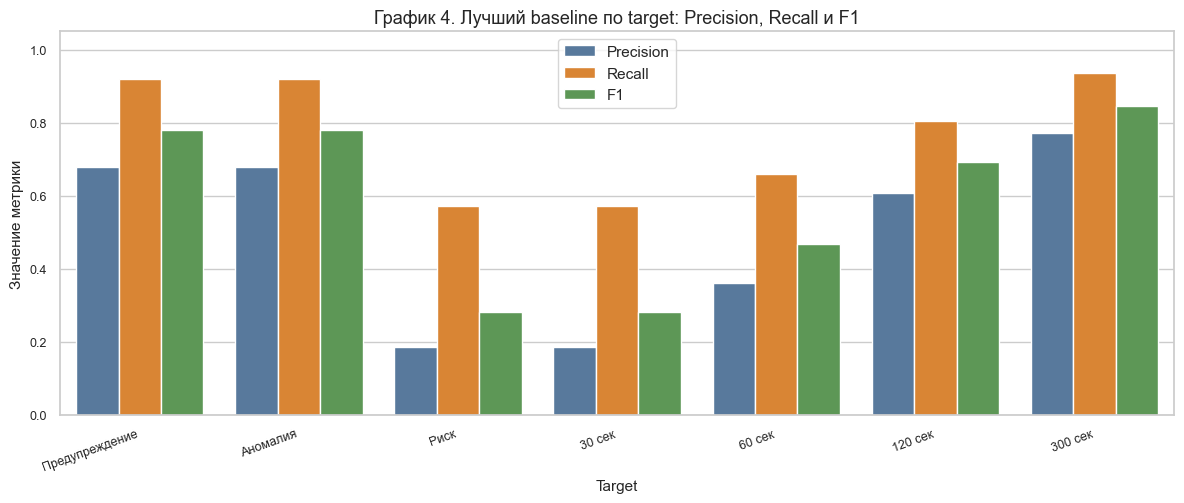

In [6]:
best_by_target = (
    test_best_f1.sort_values(["target", "f1", "average_precision"], ascending=[True, False, False])
    .groupby("target", as_index=False)
    .head(1)
    .copy()
)
best_by_target["target_label"] = best_by_target["target"].map(label_target)
best_by_target["baseline_label"] = best_by_target["baseline"].map(label_baseline)
best_by_target["target_order"] = best_by_target["target"].map({t: i for i, t in enumerate(TARGET_ORDER)})
best_by_target = best_by_target.sort_values("target_order")

display(
    best_by_target[
        ["target_label", "baseline_label", "precision", "recall", "f1", "average_precision", "roc_auc", "false_positives", "missed_anomalies"]
    ]
    .rename(columns={"target_label": "target", "baseline_label": "baseline"})
    .round(4)
    .style.hide(axis="index")
)

plot_metrics = best_by_target.melt(
    id_vars=["target", "target_label", "baseline_label"],
    value_vars=["precision", "recall", "f1"],
    var_name="metric",
    value_name="value",
)
plot_metrics["metric"] = plot_metrics["metric"].map({"precision": "Precision", "recall": "Recall", "f1": "F1"})

plt.figure(figsize=(12, 5.2))
ax = sns.barplot(
    data=plot_metrics,
    x="target_label",
    y="value",
    hue="metric",
    palette=["#4C78A8", "#F58518", "#54A24B"],
)
ax.set_title("График 4. Лучший baseline по target: Precision, Recall и F1")
ax.set_xlabel("Target")
ax.set_ylabel("Значение метрики")
ax.set_ylim(0, 1.05)
ax.legend(title="")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()


На этом графике видно, что baseline чаще выигрывает за счет Recall, а не за счет чистого Precision.

Для `horizon_300s` картина лучшая: Precision = 0.772, Recall = 0.936, F1 = 0.846. Для `horizon_120s` результат рабочий, но компромиссный: Precision = 0.608, Recall = 0.803, F1 = 0.692. То есть pipeline находит большую часть positive-окон, но платит заметным числом ложных тревог.

Для `horizon_60s` Precision падает до 0.361 при Recall = 0.660. Это уже похоже на ранний, но грязный канал. `horizon_30s` и `y_risk` еще слабее: Precision = 0.186, Recall = 0.571, F1 = 0.280. Как проверка pipeline это полезно: мы видим, где данные дают сигнал, а где простая постановка пока слишком шумная.


## 7. Проверка ошибок в обычных количествах

Метрики удобны, но для отчета полезно показать и реальные количества окон. Здесь лучший baseline по каждому target раскладывается на `TP`, `TN`, `FP`, `FN`: правильно найденные positives, правильно отсеянные normal, ложные тревоги и пропуски.


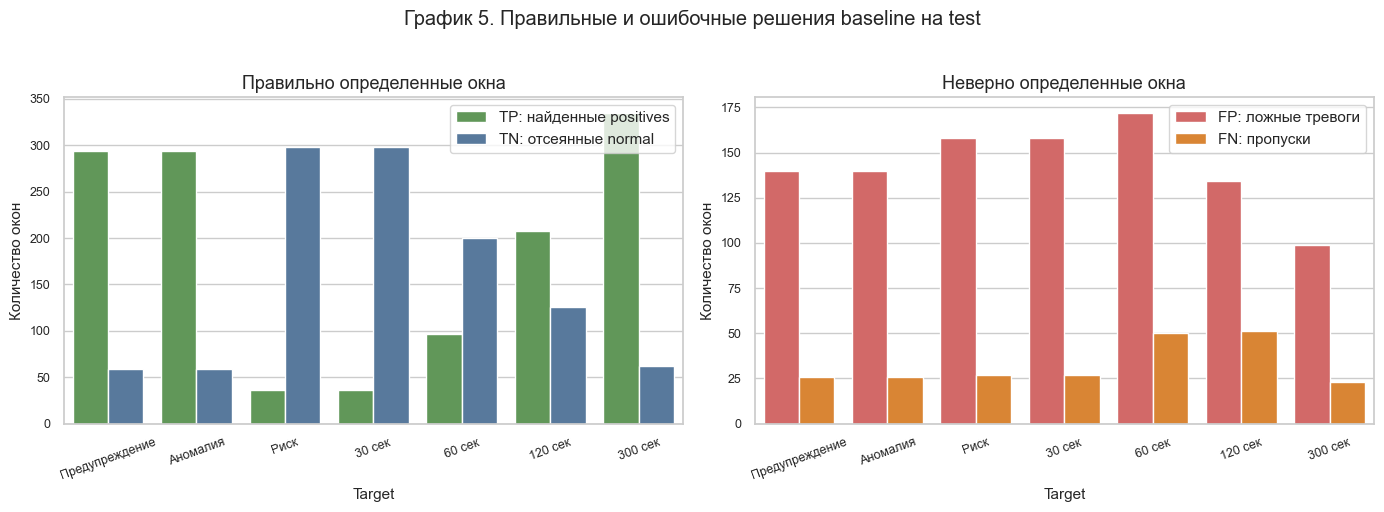

In [7]:
confusion_view = add_confusion_columns(best_by_target)
confusion_view["target_label"] = confusion_view["target"].map(label_target)

correct_long = confusion_view.melt(
    id_vars=["target_label"],
    value_vars=["tp", "tn"],
    var_name="type",
    value_name="count",
)
correct_long["type"] = correct_long["type"].map({"tp": "TP: найденные positives", "tn": "TN: отсеянные normal"})

error_long = confusion_view.melt(
    id_vars=["target_label"],
    value_vars=["fp", "fn"],
    var_name="type",
    value_name="count",
)
error_long["type"] = error_long["type"].map({"fp": "FP: ложные тревоги", "fn": "FN: пропуски"})

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(data=correct_long, x="target_label", y="count", hue="type", palette=["#59A14F", "#4C78A8"], ax=axes[0])
axes[0].set_title("Правильно определенные окна")
axes[0].set_xlabel("Target")
axes[0].set_ylabel("Количество окон")
axes[0].tick_params(axis="x", rotation=20)
axes[0].legend(title="")

sns.barplot(data=error_long, x="target_label", y="count", hue="type", palette=["#E45756", "#F58518"], ax=axes[1])
axes[1].set_title("Неверно определенные окна")
axes[1].set_xlabel("Target")
axes[1].set_ylabel("Количество окон")
axes[1].tick_params(axis="x", rotation=20)
axes[1].legend(title="")

fig.suptitle("График 5. Правильные и ошибочные решения baseline на test", y=1.02)
plt.tight_layout()
plt.show()


Количества ошибок показывают цену метрик. Для `horizon_300s` baseline находит 335 positive-окон из 358 и пропускает 23, но ошибочно поднимает 99 normal-окон. Для `horizon_120s` баланс слабее: 208 найденных positives, 51 пропуск и 134 ложные тревоги. Для `horizon_60s` false positives еще больше - 172.

Это важная проверка pipeline: он не сломан и действительно находит positives, но простой baseline еще не дает аккуратный alert-режим. В `03` будет важно смотреть, снижает ли финальная модель ложные тревоги без обвала Recall.


## 8. Score, порог и workload как диагностика pipeline

Последние графики не добавляют новый baseline, а проверяют качество самого score. Если normal и positive сильно перекрываются, проблема не решается одним порогом. Если FP-budget резко снижает Recall, значит тихий режим стоит слишком дорого. Если отдельные workload дают много ошибок, средняя метрика не может считаться полной оценкой.


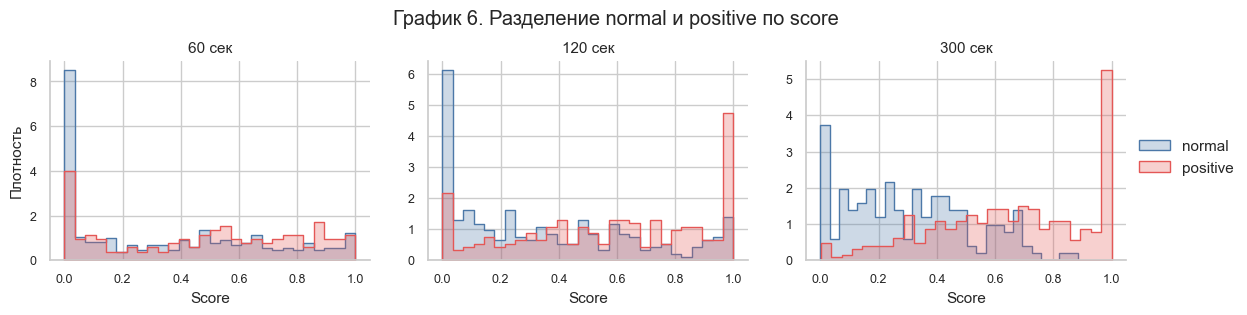

In [8]:
if predictions.empty:
    print("Файл predictions не найден, score-графики недоступны.")
else:
    predictions["score"] = pd.to_numeric(predictions["score"], errors="coerce")
    predictions["target"] = pd.to_numeric(predictions["target"], errors="coerce").fillna(0).astype(int)

    sep_targets = [t for t in ["horizon_60s", "horizon_120s", "horizon_300s"] if t in best_by_target["target"].values]
    sep_rows = []
    for target in sep_targets:
        row = best_by_target[best_by_target["target"] == target].iloc[0]
        g = predictions[
            (predictions["pred_split"].astype(str) == "test")
            & (predictions["target_name"].astype(str) == target)
            & (predictions["baseline"].astype(str) == row["baseline"])
        ].copy()
        if g.empty:
            continue
        g["target_label"] = label_target(target)
        g["class_label"] = np.where(g["target"] == 1, "positive", "normal")
        sep_rows.append(g)

    if sep_rows:
        sep_df = pd.concat(sep_rows, ignore_index=True)
        grid = sns.FacetGrid(
            sep_df,
            col="target_label",
            hue="class_label",
            col_wrap=3,
            sharex=False,
            sharey=False,
            height=3.2,
            aspect=1.2,
            palette={"normal": "#4C78A8", "positive": "#E45756"},
        )
        grid.map_dataframe(
            sns.histplot,
            x="score",
            stat="density",
            common_norm=False,
            bins=28,
            element="step",
            fill=True,
            alpha=0.28,
        )
        grid.add_legend(title="")
        grid.set_axis_labels("Score", "Плотность")
        grid.set_titles("{col_name}")
        grid.fig.subplots_adjust(top=0.82)
        grid.fig.suptitle("График 6. Разделение normal и positive по score")
        plt.show()


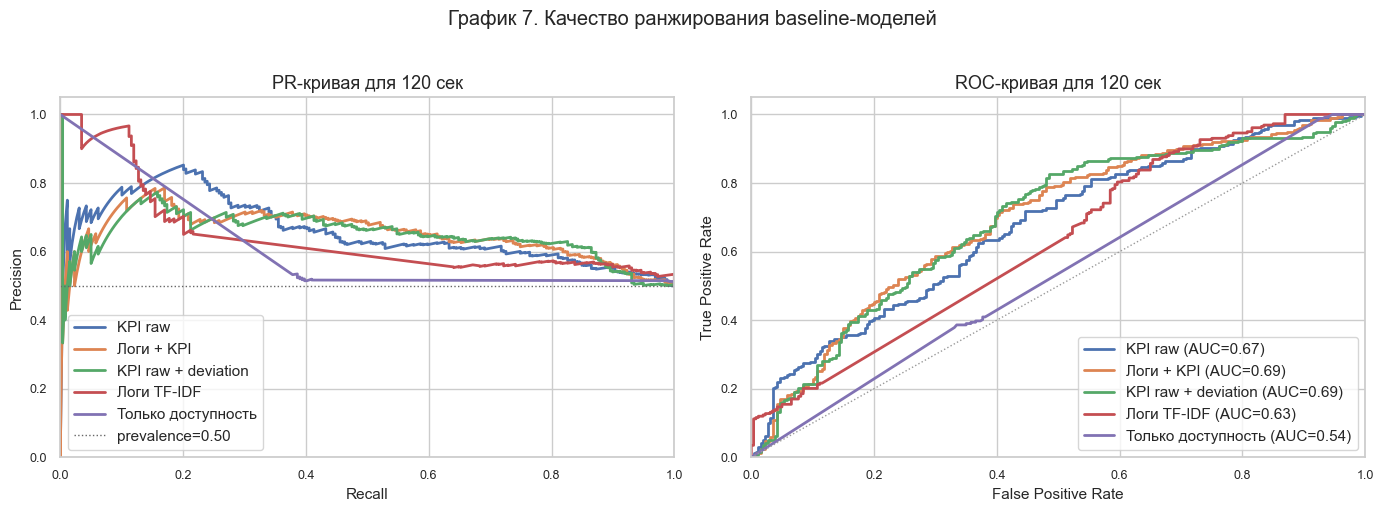

In [9]:
if predictions.empty:
    print("Нет predictions для PR/ROC.")
else:
    curve_target = "horizon_120s" if "horizon_120s" in test_best_f1["target"].values else test_best_f1["target"].iloc[0]
    curve_baselines = (
        test_best_f1[test_best_f1["target"] == curve_target]
        .sort_values("average_precision", ascending=False)["baseline"]
        .drop_duplicates()
        .head(5)
        .tolist()
    )

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    plotted = 0
    prevalence = None
    for baseline in curve_baselines:
        g = predictions[
            (predictions["pred_split"].astype(str) == "test")
            & (predictions["target_name"].astype(str) == curve_target)
            & (predictions["baseline"].astype(str) == baseline)
        ].copy()
        if g.empty:
            continue
        y = pd.to_numeric(g["target"], errors="coerce").fillna(0).astype(int).to_numpy()
        s = pd.to_numeric(g["score"], errors="coerce").fillna(0).to_numpy()
        if len(np.unique(y)) < 2:
            continue
        pr, rc, _ = precision_recall_curve(y, s)
        fpr, tpr, _ = roc_curve(y, s)
        prevalence = float(y.mean())
        axes[0].plot(rc, pr, linewidth=2.0, label=label_baseline(baseline))
        axes[1].plot(fpr, tpr, linewidth=2.0, label=f"{label_baseline(baseline)} (AUC={auc(fpr, tpr):.2f})")
        plotted += 1

    if plotted:
        if prevalence is not None:
            axes[0].axhline(prevalence, color="#666666", linestyle=":", linewidth=1, label=f"prevalence={prevalence:.2f}")
        axes[0].set_title(f"PR-кривая для {label_target(curve_target)}")
        axes[0].set_xlabel("Recall")
        axes[0].set_ylabel("Precision")
        axes[0].set_xlim(0, 1)
        axes[0].set_ylim(0, 1.05)
        axes[0].legend(title="")
        axes[1].plot([0, 1], [0, 1], color="#999999", linestyle=":", linewidth=1)
        axes[1].set_title(f"ROC-кривая для {label_target(curve_target)}")
        axes[1].set_xlabel("False Positive Rate")
        axes[1].set_ylabel("True Positive Rate")
        axes[1].set_xlim(0, 1)
        axes[1].set_ylim(0, 1.05)
        axes[1].legend(title="")
        fig.suptitle("График 7. Качество ранжирования baseline-моделей", y=1.02)
        plt.tight_layout()
        plt.show()


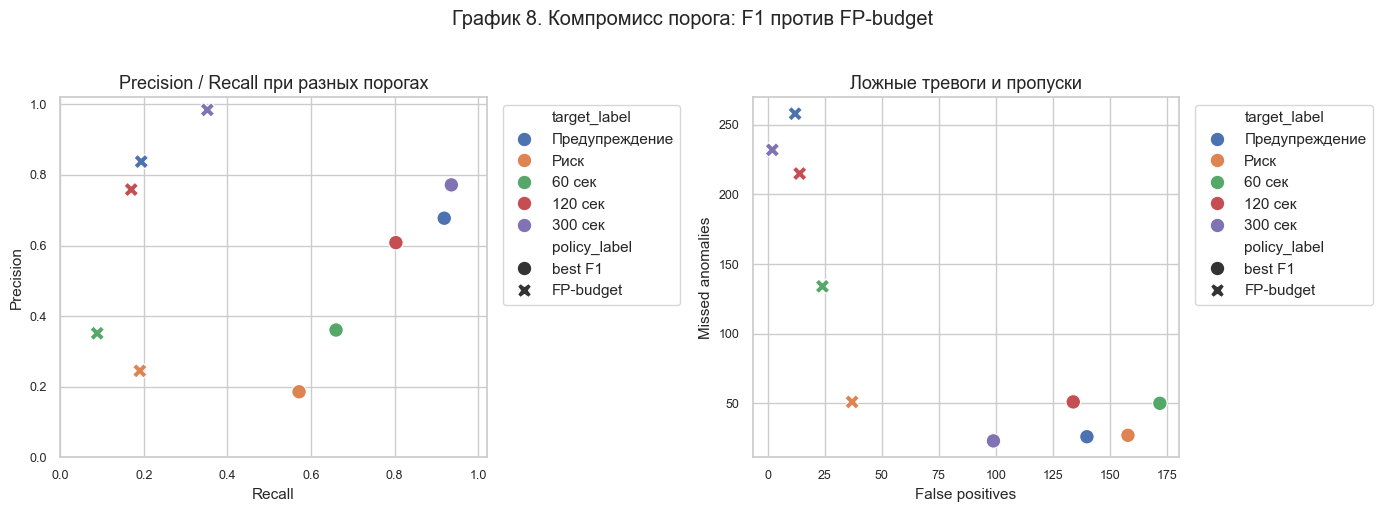

In [10]:
fp_budget = metrics[
    (metrics["split"].astype(str) == "test")
    & (metrics["threshold_policy"].astype(str).str.contains("fp_budget", regex=False))
].copy()
best_keys = best_by_target[["target", "baseline"]].drop_duplicates()
policy_compare = pd.concat([test_best_f1, fp_budget], ignore_index=True).merge(best_keys, on=["target", "baseline"], how="inner")
policy_compare = policy_compare[policy_compare["target"].isin([t for t in KEY_TARGETS if t in policy_compare["target"].unique()])].copy()
policy_compare["target_label"] = policy_compare["target"].map(label_target)
policy_compare["policy_label"] = np.where(
    policy_compare["threshold_policy"].astype(str).str.contains("fp_budget", regex=False),
    "FP-budget",
    "best F1",
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
if not policy_compare.empty:
    sns.scatterplot(data=policy_compare, x="recall", y="precision", hue="target_label", style="policy_label", s=110, ax=axes[0])
    axes[0].set_title("Precision / Recall при разных порогах")
    axes[0].set_xlabel("Recall")
    axes[0].set_ylabel("Precision")
    axes[0].set_xlim(0, 1.02)
    axes[0].set_ylim(0, 1.02)
    axes[0].legend(title="", bbox_to_anchor=(1.02, 1), loc="upper left")

    sns.scatterplot(data=policy_compare, x="false_positives", y="missed_anomalies", hue="target_label", style="policy_label", s=110, ax=axes[1])
    axes[1].set_title("Ложные тревоги и пропуски")
    axes[1].set_xlabel("False positives")
    axes[1].set_ylabel("Missed anomalies")
    axes[1].legend(title="", bbox_to_anchor=(1.02, 1), loc="upper left")
else:
    for ax in axes:
        ax.text(0.5, 0.5, "Нет данных для FP-budget", ha="center", va="center")
        ax.axis("off")
fig.suptitle("График 8. Компромисс порога: F1 против FP-budget", y=1.02)
plt.tight_layout()
plt.show()


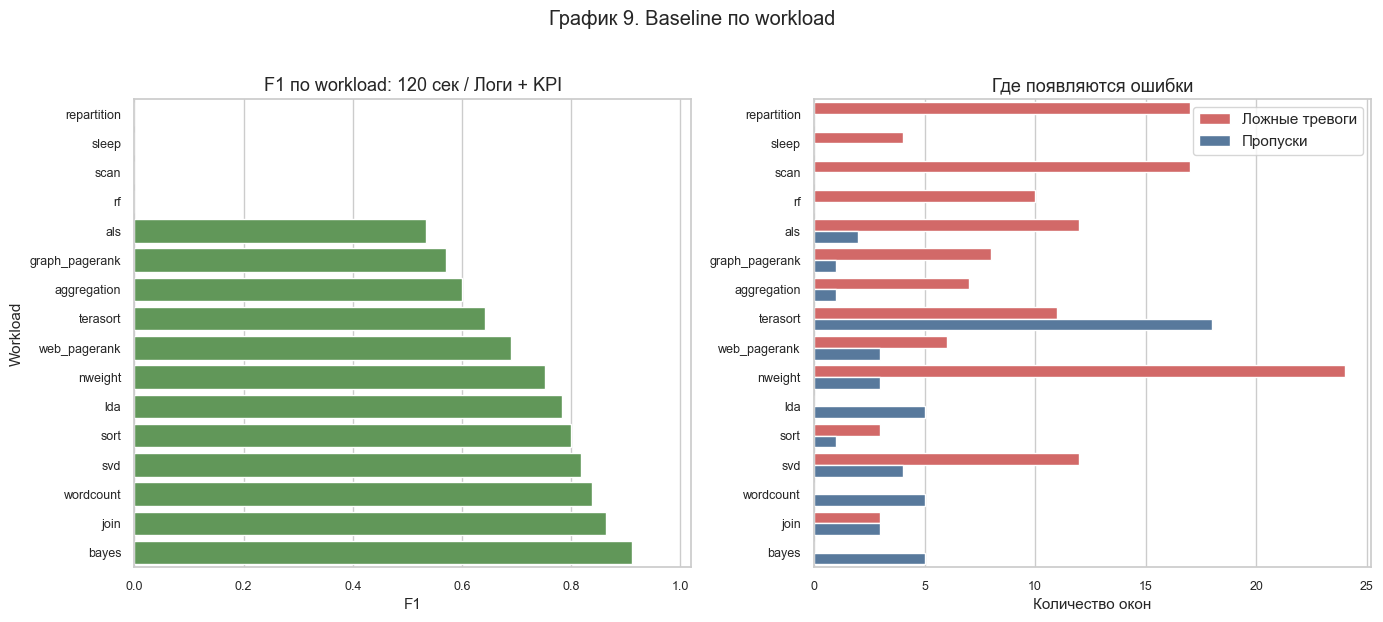

In [11]:
if workload_metrics.empty:
    print("baseline_protocol_workload_metrics.csv не найден.")
else:
    workload_metrics = numeric_cols(workload_metrics, metric_cols + ["n", "positives", "prevalence"])
    focus_target = "horizon_120s" if "horizon_120s" in best_by_target["target"].values else best_by_target["target"].iloc[0]
    focus_baseline = best_by_target[best_by_target["target"] == focus_target]["baseline"].iloc[0]
    focus_w = workload_metrics[
        (workload_metrics["target"].astype(str) == focus_target)
        & (workload_metrics["baseline"].astype(str) == focus_baseline)
    ].copy()
    focus_w = focus_w.sort_values("f1", ascending=True)

    fig, axes = plt.subplots(1, 2, figsize=(14, max(5, 0.38 * len(focus_w))))
    if not focus_w.empty:
        sns.barplot(data=focus_w, x="f1", y="workload", color="#59A14F", ax=axes[0])
        axes[0].set_title(f"F1 по workload: {label_target(focus_target)} / {label_baseline(focus_baseline)}")
        axes[0].set_xlabel("F1")
        axes[0].set_ylabel("Workload")
        axes[0].set_xlim(0, 1.02)

        errors = focus_w.melt(id_vars=["workload"], value_vars=["false_positives", "missed_anomalies"], var_name="error_type", value_name="count")
        errors["error_type"] = errors["error_type"].map({"false_positives": "Ложные тревоги", "missed_anomalies": "Пропуски"})
        sns.barplot(data=errors, x="count", y="workload", hue="error_type", palette=["#E45756", "#4C78A8"], ax=axes[1])
        axes[1].set_title("Где появляются ошибки")
        axes[1].set_xlabel("Количество окон")
        axes[1].set_ylabel("")
        axes[1].legend(title="")
    fig.suptitle("График 9. Baseline по workload", y=1.02)
    plt.tight_layout()
    plt.show()


Эти диагностические графики показывают, где pipeline проходит проверку, а где появляются ограничения.

Распределения score объясняют, почему ранние горизонты сложнее: normal и positive заметно перекрываются, поэтому порогом нельзя создать идеальное разделение. Для `horizon_120s` несколько baseline-моделей близки друг к другу: AP у `metric_raw` немного выше (0.659), но лучший F1 дает `fused_log_metric` (0.692), а ROC-AUC у него умеренный - 0.693.

FP-budget показывает цену более тихого режима: для `horizon_120s` false positives падают со 134 до 14, но Recall падает с 0.803 до 0.170. Workload-разбор тоже важен: на `bayes`, `join`, `wordcount` baseline работает уверенно, но на `scan` и `repartition` появляются ложные тревоги даже при отсутствии positives. Значит, pipeline проходит базовую проверку, но будущая модель должна улучшать не только средний F1, а и устойчивость по workload и поведение при ограничении ложных срабатываний.


## Итог 02

Этот notebook в первую очередь построил и проверил baseline-пайплайн. Мы убедились, что strict contract читается, split и target используются воспроизводимо, baseline-артефакты формируются, а evaluation считает не только F1, но и Precision, Recall, TP/TN/FP/FN, score separation, FP-budget и workload-breakdown.

Baseline как диагностический инструмент показал, что в данных есть сигнал: F1 = 0.846 для `horizon_300s`, F1 = 0.780 для `y_warning / y_anomaly`, F1 = 0.692 для `horizon_120s`. Но он же показал ограничения: `horizon_60s`, `horizon_30s` и `y_risk` остаются шумными, а высокий Recall часто достигается большим числом false positives.

Значит, в `03` финальная Efficient HADES модель должна сравниваться не с абстрактной нулевой линией, а с этим baseline-контуром. Ее задача - показать, что усложнение архитектуры дает пользу поверх уже проверенного pipeline: лучшее разделение score, меньше ложных тревог, устойчивость по workload и сохранение Recall на ранних горизонтах.
